# v5 — Clean `funder` / `installer`: lowercase, strip, collapse rare levels

**What v5 adds.** For `funder` and `installer` (free text, ~1,900 and ~2,100 distinct values): lowercase + strip, then collapse every level seen fewer than 20 times in the training split into `"other"`. Everything else is v4's stack: `geo_cluster` (k=30), v3's search, early stopping, **and balanced weights**.

**Hypotheses.**
- **H7b** — typos and case variants of the same entity waste model capacity, so cleaning sharpens splits.
- **H5‴** — weights cost accuracy (confirmed at v2, v3, v4). Main protocol here is **no weights**.
- **H8 (new, from the v4 notebook)** — `ward` (2,092 levels) and `lga` (125) carry 16% and 13% of total gain. High-cardinality categoricals may be *overfit*. If so, collapsing them helps more than cleaning funder/installer.

**Protocol.** v3's searched params, 300 trees, no weights, same folds, reference = v4 row 4a (`geo_cluster` k=30, no cleaning) **0.8111**. Features are fit inside each fold, so the rare-level cut is learned on the training fold only.

| row | change vs reference | 
|---|---|
| ref | v4 row 4a (read from `results.jsonl`) |
| 5a | lowercase + strip only (no collapse) |
| 5b | + collapse `< 20` → other (**v5's feature**) |
| 5c | collapse `< 5` (milder) |
| 5d | collapse `< 100` (harsher) |
| 5e | 5b + also collapse `ward` and `lga` at `< 20` (**H8**) |
| 5f | drop `funder` and `installer` entirely |
| 5g | **v5 as shipped**: 5b + early stopping on val fold + **weights** |

In [1]:
import sys, warnings, json
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 140)
df, y, le = get_train('v5')
Flex = make_flex('v5')
BEST = json.loads(open('cache/v3_search.json').read())['best_params']
ref = next(r for r in map(json.loads, RESULTS.read_text().splitlines()) if r['label'].startswith('4a '))
print(f"reference 4a (k=30, no cleaning, no weights): {ref['mean']:.4f} ± {ref['std']:.4f}")
FT = ['funder', 'installer']

def run(label, flex_kw, **kw):
    sc, oof, it = cv_xgb_es(df, y, lambda: Flex(k=30, **flex_kw), BEST, **kw)
    r = log_result('v5', label, sc)
    d = np.array(sc) - np.array(ref['folds'])
    print(f"{label:<46} {r['mean']:.4f} ± {r['std']:.4f}   Δ vs ref {d.mean():+.4f}  per-fold {np.round(d, 4).tolist()}")
    return sc, oof

reference 4a (k=30, no cleaning, no weights): 0.8111 ± 0.0034


## What does the cleaning actually do to the levels?

In [2]:
X = df.drop(columns=[TARGET])
rows = []
for c in FT:
    low = X[c].str.lower().str.strip()
    cnt = low.value_counts()
    rows.append({'column': c, 'raw levels': X[c].nunique(), 'after lower/strip': low.nunique(),
                 'levels with ≥20 rows': int((cnt >= 20).sum()), 'rows in rare (<20) levels': f"{cnt[cnt < 20].sum()} ({cnt[cnt < 20].sum()/len(X):.1%})",
                 'top-10 share': f"{cnt.head(10).sum()/len(X):.0%}"})
pd.DataFrame(rows).set_index('column')

,raw levels,after lower/strip,levels with ≥20 rows,rows in rare (<20) levels,top-10 share
column,,,,,
funder,1896,1896,269,4973 (8.4%),38%
installer,2145,1935,249,5086 (8.6%),46%


## 5a — lowercase + strip only

In [3]:
sc_a, _ = run('5a lower/strip only', dict(text=dict(cols=FT, min=0)), es='none')

5a lower/strip only                            0.8108 ± 0.0044   Δ vs ref -0.0003  per-fold [0.001, 0.0003, -0.0019, -0.0015, 0.0008]


## 5b — collapse `< 20` → other (v5's feature)

In [4]:
sc_b, oof_b = run('5b collapse <20 (v5 feature)', dict(text=dict(cols=FT, min=20)), es='none')

5b collapse <20 (v5 feature)                   0.8115 ± 0.0036   Δ vs ref +0.0005  per-fold [0.0013, -0.0013, 0.0008, 0.0003, 0.001]


## 5c / 5d — collapse threshold sweep (5, 100)

In [5]:
sc_c, _ = run('5c collapse <5', dict(text=dict(cols=FT, min=5)), es='none')
sc_d, _ = run('5d collapse <100', dict(text=dict(cols=FT, min=100)), es='none')

5c collapse <5                                 0.8114 ± 0.0041   Δ vs ref +0.0003  per-fold [0.0005, 0.0006, 0.0003, -0.0015, 0.0018]


5d collapse <100                               0.8107 ± 0.0041   Δ vs ref -0.0004  per-fold [0.001, -0.001, -0.0014, -0.0009, 0.0006]


## 5e — H8: also collapse `ward` and `lga`

In [6]:
sc_e, _ = run('5e 5b + collapse ward, lga <20 (H8)', dict(text=dict(cols=FT + ['ward', 'lga'], min=20)), es='none')

5e 5b + collapse ward, lga <20 (H8)            0.8119 ± 0.0040   Δ vs ref +0.0008  per-fold [0.0022, -0.0003, 0.0, 0.0005, 0.0018]


## 5f — drop `funder` and `installer`

In [7]:
sc_f, _ = run('5f drop funder + installer', dict(drop=FT), es='none')

5f drop funder + installer                     0.8090 ± 0.0034   Δ vs ref -0.0021  per-fold [-0.0012, -0.003, -0.0016, -0.0007, -0.004]


## 5g — v5 as shipped (cleaning + early stopping on val fold + balanced weights)

In [8]:
sc_g, oof_g = run('5g v5 as shipped (val ES + weights)', dict(text=dict(cols=FT, min=20)), es='val', balanced=True)

5g v5 as shipped (val ES + weights)            0.7817 ± 0.0047   Δ vs ref -0.0294  per-fold [-0.0265, -0.0327, -0.0312, -0.0295, -0.0271]


## Results

In [9]:
res = pd.DataFrame([r for r in map(json.loads, RESULTS.read_text().splitlines()) if r['version'] == 'v5'])
res['acc'] = res['mean'].round(4); res['fold std'] = res['std'].round(4)
res['Δ vs ref'] = (res['mean'] - ref['mean']).round(4)
res[['label', 'acc', 'fold std', 'Δ vs ref']].set_index('label')

,acc,fold std,Δ vs ref
label,,,
5a lower/strip only,0.8108,0.0044,-0.0003
5b collapse <20 (v5 feature),0.8115,0.0036,0.0005
5c collapse <5,0.8114,0.0041,0.0003
5d collapse <100,0.8107,0.0041,-0.0004
"5e 5b + collapse ward, lga <20 (H8)",0.8119,0.0040,0.0008
5f drop funder + installer,0.8090,0.0034,-0.0021
5g v5 as shipped (val ES + weights),0.7817,0.0047,-0.0294


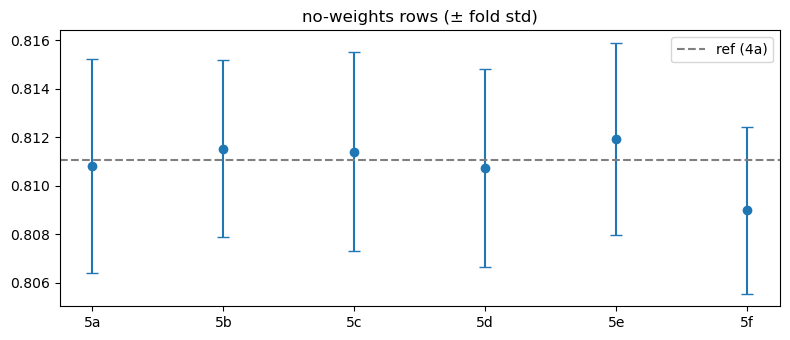

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sub = res.iloc[:-1]
ax.errorbar(range(len(sub)), sub['mean'], yerr=sub['std'], fmt='o', capsize=4)
ax.axhline(ref['mean'], ls='--', c='gray', label='ref (4a)'); ax.legend()
ax.set_xticks(range(len(sub))); ax.set_xticklabels([l.split()[0] for l in sub.label]); ax.set_title('no-weights rows (± fold std)')
plt.tight_layout(); plt.show()

## Conclusion

Searched params, 300 trees, same folds, reference = v4 row 4a (k=30, no cleaning, no weights) **0.8111 ± 0.0034**.

| row | CV accuracy | Δ vs ref |
|---|---|---|
| 5a lowercase + strip only | 0.8108 ± 0.0044 | −0.0003 |
| 5b collapse < 20 (**v5's feature**) | 0.8115 ± 0.0036 | +0.0005 |
| 5c collapse < 5 | 0.8114 ± 0.0041 | +0.0003 |
| 5d collapse < 100 | 0.8107 ± 0.0041 | −0.0004 |
| 5e 5b + also collapse `ward`, `lga` (H8) | 0.8119 ± 0.0040 | +0.0008 |
| 5f drop `funder` + `installer` | 0.8090 ± 0.0034 | **−0.0021** |
| **5g v5 as shipped (val ES + weights)** | **0.7817 ± 0.0047** | **−0.0294** |

- **H7b (cleaning sharpens splits) is not supported.** Every cleaning variant sits within ±0.0008 of the reference, far inside the fold std (~0.004), with mixed per-fold signs. The threshold sweep (5, 20, 100) shows no trend either.
- **The premise was overstated.** The level table shows `funder` has **no** case/spacing variants at all (1,896 raw levels → 1,896 after lowercase/strip), and `installer` only 2,145 → 1,935. Rare levels (< 20 rows) hold only ~8.5% of rows in each column. There is little messiness for the cleaning to remove, and trees were already handling it.
- **The columns still matter a little.** Dropping `funder` and `installer` costs −0.0021, and **all 5 folds are negative** (−0.0007 to −0.004). That is the most consistent effect in this notebook, but it is about half the fold std, so I'd call it a small real signal, not a large one.
- **H8 (high-cardinality `ward`/`lga` overfit) is not supported.** Collapsing them too (5e) gives +0.0008, which is a fifth of the fold std (4 of 5 folds are ≥ 0, mostly small). Their large share of gain in the v4 notebook reflects real use of the signal, not harmful overfitting, at least at this tree depth.
- **Weights, a fourth time.** v5 as shipped scores 0.7817, about 0.03 below the same features without weights, matching v3 (0.7818) and v4 (0.7813). Three consecutive "improvements" (v3, v4, v5) changed the shipped score by less than 0.001.

**Caveats.** One seed, v3's params reused (v5 re-searched), CV only, no leaderboard. A rare-level cut might matter more for a different model class (linear, or a small tree depth), which I did not test.

**Running total.** Honest best is still ≈ 0.811. v1's all-feature XGBoost (0.809) is within noise of every no-weights row since. The only changes that moved accuracy beyond noise in v1–v5 were *removing* the top-15 cut (+0.006) and the class weights (+0.03), and keeping `funder`/`installer` (+0.002).

Next: **v6** adds interaction features (`quantity × waterpoint_type`, `payment × management`, population density ratio).